# 02 · Hyperbolic embeddings

Companion notebook for *Questioning the mathematical foundations of AI*, Dr Ana Rojo-Echeburúa, PyCon España 2026.

## What this notebook does

Notebook 01 ended with a problem. Cosine similarity in flat space gives "a dog is an animal" and "an animal is a dog" the same score, so it has nowhere to put a hierarchy. And hierarchies are everywhere in real data: product catalogues, charts of accounts, org charts, medical codes, WordNet.

Here we try a different space. Hyperbolic space is curved so that there's more and more room the further you go from the centre, which is exactly the shape of a tree. You'll build the Poincaré disk (the most popular picture of hyperbolic space) from scratch, train a hierarchy into it, race it against flat space on the same data, and then look at what the research says about hyperbolic retrieval and LLMs, including the bits that still hurt.

## The steps

1. **Why flat space struggles with trees.** Trees grow exponentially, flat space doesn't.
2. **Three curvatures.** Sphere, flat and hyperbolic, in one picture.
3. **The Poincaré disk from scratch.** The distance formula in numpy, and a tree drawn in the disk.
4. **Train a hierarchy in 2D.** gensim's `PoincareModel` on a tiny taxonomy.
5. **Flat vs hyperbolic, same data.** Same tree, same loss, same budget, two geometries.
6. **geoopt.** The PyTorch library that does the curved-space bookkeeping for you.
7. **Results from retrieval and LLMs.** What the published numbers say.
8. **The costs.** Precision, optimisation and vector databases.

## Setup

Imports, seed 0 everywhere and the slide colours. We store points in the disk as **complex numbers** in a few places, because the symmetries of the disk are fractions of complex numbers and that makes them one line of code.

In [1]:
import os
import random
import warnings
import logging

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import torch
import geoopt
import gensim
from gensim.models.poincare import PoincareModel

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BG, TEXT = "#CFD5D3", "#030303"
BROWN, DARK_BROWN, SLATE, LIGHT_GREY = "#7F584A", "#4F3733", "#767F87", "#A9B0B4"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "figure.dpi": 110,
})

def draw_disk(ax, title=None):
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=TEXT, lw=1.2))
    ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title)

print("gensim", gensim.__version__, "| geoopt", geoopt.__version__, "| torch", torch.__version__)

gensim 4.4.0 | geoopt 0.5.1 | torch 2.15.0


**What you're seeing:** nothing to look at yet, just the versions. Every output in this notebook was produced with exactly these, so if yours differ slightly, check the versions first.

## Step 1 · Why flat space struggles with trees

Think of a binary tree. Level 0 has 1 node, level 1 has 2, level 2 has 4, and level $d$ has $2^d$. The number of nodes doubles at every level, so it grows **exponentially** with depth.

Now think about how much room flat space gives you. A disc of radius $r$ in the plane has area $\pi r^2$, and a ball in $n$ dimensions has volume proportional to $r^n$. That grows like a **polynomial** in $r$, and any exponential eventually beats any polynomial. So if you place the levels of a tree at distances $1, 2, 3, \dots$ from the root, the deep levels run out of room and nodes that should be far apart in the tree get squashed together.

Hyperbolic space grows like $e^r$. A disc of radius $r$ in the hyperbolic plane has area $2\pi(\cosh r - 1)$, which is exponential, just like the tree.

The theory backs this up. Bourgain (Israel J. Math., 1986) showed that embedding a complete binary tree of depth $k$ in Euclidean space, in any number of dimensions, needs a distortion that grows like $\sqrt{\log k}$. Sarkar (Graph Drawing, 2011) showed that any tree embeds in the hyperbolic plane, in just **2** dimensions, with distortion as close to 1 as you like.

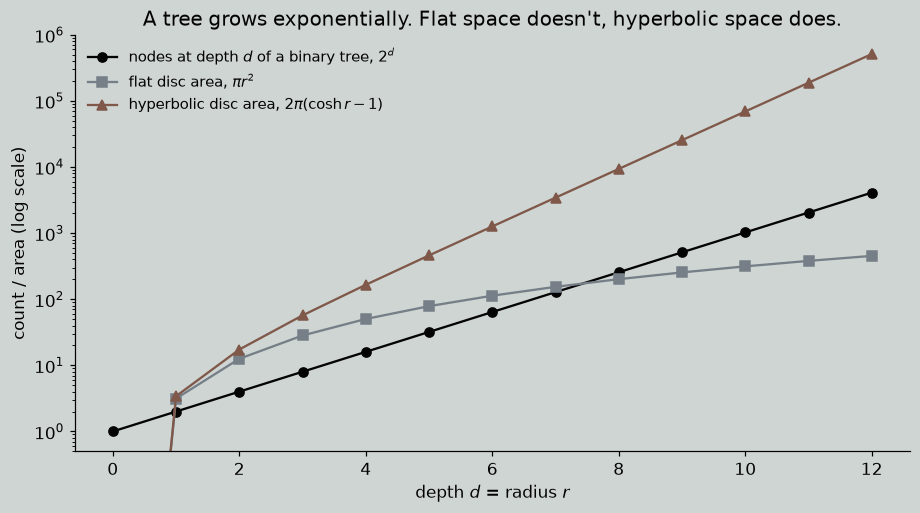

depth  4:  tree nodes     16   flat area        50   hyperbolic area          165
depth  8:  tree nodes    256   flat area       201   hyperbolic area        9,359
depth 12:  tree nodes  4,096   flat area       452   hyperbolic area      511,303


In [2]:
d = np.arange(0, 13)
r = d.astype(float)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.semilogy(d, 2.0 ** d, "o-", color=TEXT, label=r"nodes at depth $d$ of a binary tree, $2^d$")
ax.semilogy(r, np.pi * r ** 2 + 1e-9, "s-", color=SLATE, label=r"flat disc area, $\pi r^2$")
ax.semilogy(r, 2 * np.pi * (np.cosh(r) - 1) + 1e-9, "^-", color=BROWN, label=r"hyperbolic disc area, $2\pi(\cosh r - 1)$")
ax.set_xlabel("depth $d$ = radius $r$")
ax.set_ylabel("count / area (log scale)")
ax.set_ylim(0.5, 1e6)
ax.set_title("A tree grows exponentially. Flat space doesn't, hyperbolic space does.")
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.show()

for k in [4, 8, 12]:
    print(f"depth {k:>2}:  tree nodes {2**k:>6,}   flat area {np.pi*k**2:>9,.0f}   hyperbolic area {2*np.pi*(np.cosh(k)-1):>12,.0f}")

**What you're seeing:** on a log scale an exponential is a straight line, and the tree and the hyperbolic area are both straight lines while the flat area bends over. By depth 12 a binary tree has 4,096 nodes on that level alone, and the flat disc only has an area of 452 to put them in. The hyperbolic disc has over 500,000. That's the whole argument in one plot.

## Step 2 · Three curvatures

Curvature says how space bends. A neat way to feel it is to draw a circle of radius $r$ (all the points at distance $r$ from a centre) and measure how long it is:

| Space | Curvature | Length of a circle of radius $r$ |
|---|---|---|
| Sphere | positive (+1) | $2\pi \sin r$ |
| Flat plane | zero | $2\pi r$ |
| Hyperbolic plane | negative (−1) | $2\pi \sinh r$ |

On a sphere, circles grow more slowly than you'd expect and then shrink again (walk away from the North Pole and the circles of latitude get bigger until the equator, then smaller). In hyperbolic space they grow faster and faster. That extra room is what we'll use for trees.

Remember this from notebook 01. Once you normalise embeddings to length 1 and compare them with cosine, they already live on a sphere. So the default in retrieval is a positively curved space, the opposite of what a hierarchy wants.

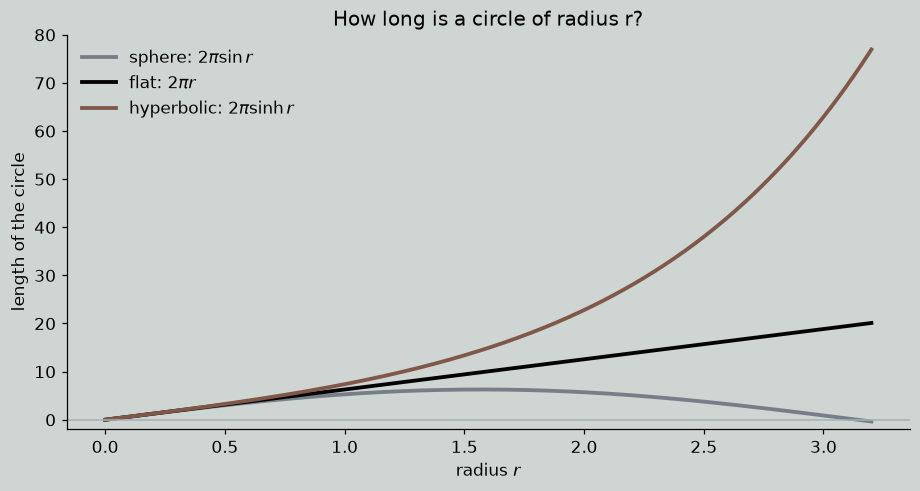

r = 1:  sphere   5.29   flat   6.28   hyperbolic    7.38
r = 2:  sphere   5.71   flat  12.57   hyperbolic   22.79
r = 3:  sphere   0.89   flat  18.85   hyperbolic   62.94


In [3]:
r = np.linspace(0, 3.2, 300)

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(r, 2 * np.pi * np.sin(r), color=SLATE, lw=2.5, label=r"sphere: $2\pi\sin r$")
ax.plot(r, 2 * np.pi * r, color=TEXT, lw=2.5, label=r"flat: $2\pi r$")
ax.plot(r, 2 * np.pi * np.sinh(r), color=BROWN, lw=2.5, label=r"hyperbolic: $2\pi\sinh r$")
ax.axhline(0, color=LIGHT_GREY, lw=1)
ax.set_xlabel("radius $r$")
ax.set_ylabel("length of the circle")
ax.set_ylim(-2, 80)
ax.set_title("How long is a circle of radius r?")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

for rr in [1, 2, 3]:
    print(f"r = {rr}:  sphere {2*np.pi*np.sin(rr):6.2f}   flat {2*np.pi*rr:6.2f}   hyperbolic {2*np.pi*np.sinh(rr):7.2f}")

**What you're seeing:** the three curves start together (zoom in far enough and every space looks flat) and then split. At radius 3 the hyperbolic circle is 62.94 long against 18.85 for the flat one, more than three times the room, while the circle on the sphere has shrunk to 0.89 because it's almost back round to the other pole.

## Step 3 · The Poincaré disk from scratch

You can't draw the whole hyperbolic plane on flat paper without distorting it, but you can squeeze it into a disc. The **Poincaré disk** is the open unit disc $\{z : |z| < 1\}$ with a different way of measuring distance:

$$d(u, v) = \operatorname{arcosh}\left(1 + \frac{2\,\lVert u - v \rVert^2}{(1 - \lVert u \rVert^2)(1 - \lVert v \rVert^2)}\right)$$

Look at the denominator. When a point gets close to the edge, $1 - \lVert u \rVert^2$ gets close to 0, so distances blow up. The edge is infinitely far away, and the disk you see is a squashed map of an infinite space. Near the centre it looks almost flat, and near the edge a tiny step on paper is a huge step in hyperbolic distance.

Let's implement it in numpy and check that.

In [4]:
def poincare_dist(u, v):
    u, v = np.asarray(u, float), np.asarray(v, float)
    num = 2 * np.sum((u - v) ** 2, axis=-1)
    den = (1 - np.sum(u ** 2, axis=-1)) * (1 - np.sum(v ** 2, axis=-1))
    return np.arccosh(1 + num / den)

print("Small steps on paper, different places in the disk:")
for x in [0.0, 0.5, 0.8, 0.89, 0.98]:
    u, v = [x, 0], [x + 0.01 if x >= 0.98 else x + 0.1, 0]
    print(f"  from ({u[0]:.2f}, 0) to ({v[0]:.2f}, 0):  flat distance {v[0]-u[0]:.2f}   hyperbolic distance {poincare_dist(u, v):.3f}")

print("\nDistance from the centre:")
for x in [0.5, 0.9, 0.99, 0.999, 0.9999]:
    print(f"  to ({x}, 0): {poincare_dist([0, 0], [x, 0]):.3f}")

Small steps on paper, different places in the disk:
  from (0.00, 0) to (0.10, 0):  flat distance 0.10   hyperbolic distance 0.201
  from (0.50, 0) to (0.60, 0):  flat distance 0.10   hyperbolic distance 0.288
  from (0.80, 0) to (0.90, 0):  flat distance 0.10   hyperbolic distance 0.747
  from (0.89, 0) to (0.99, 0):  flat distance 0.10   hyperbolic distance 2.449
  from (0.98, 0) to (0.99, 0):  flat distance 0.01   hyperbolic distance 0.698

Distance from the centre:
  to (0.5, 0): 1.099
  to (0.9, 0): 2.944
  to (0.99, 0): 5.293
  to (0.999, 0): 7.600
  to (0.9999, 0): 9.903


**What you're seeing:** the same step of 0.1 on paper is worth 0.20 near the centre, 0.75 between 0.8 and 0.9, and 2.45 between 0.89 and 0.99. Even a step of 0.01, from 0.98 to 0.99, is worth 0.70, more than three times the 0.1 step at the centre. And distance from the centre grows without limit, from 2.94 at 0.9 to 9.90 at 0.9999, with every extra 9 adding about 2.3 (which is $\ln 10$). That's what \"infinitely far away\" looks like on a finite drawing.

Now let's draw a tree in the disk. We place a binary tree of depth 5 with every level the same hyperbolic distance further from the root, and draw each edge as a **geodesic**, the hyperbolic version of a straight line. In the Poincaré disk, geodesics are arcs of circles that meet the edge at right angles (or straight lines through the centre).

To draw a geodesic from $x$ to $y$ we use a trick that comes back in notebooks 03 and 05. The map $z \mapsto (z - x)/(1 - \bar{x}z)$ is a symmetry of the disk (an isometry, so it preserves hyperbolic distance) that slides $x$ to the centre. Geodesics through the centre are straight lines, so we draw a straight segment there and slide it back.

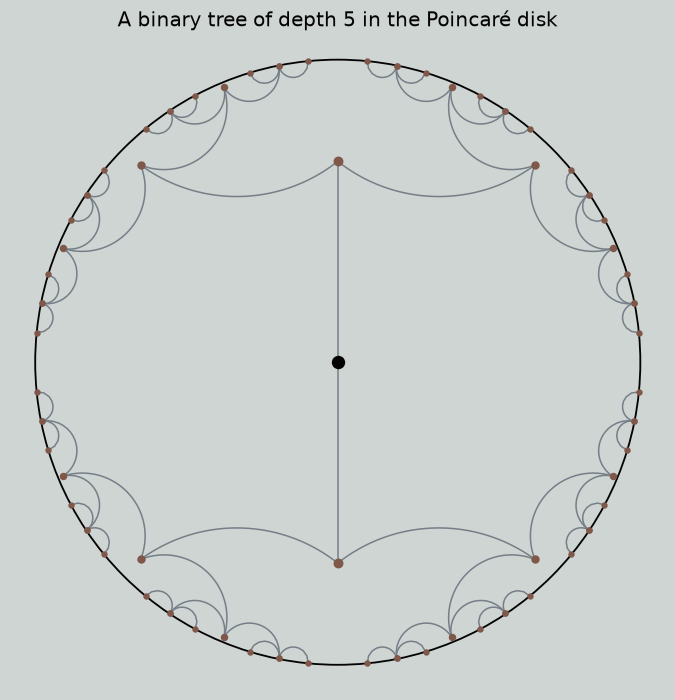

Two neighbouring leaves:  flat distance 0.196   hyperbolic distance 11.35
Each leaf to the root:    flat distance 0.999   hyperbolic distance 8.00


In [5]:
def to_centre(x):        # isometry of the disk that sends x to 0
    return lambda z: (z - x) / (1 - np.conj(x) * z)

def from_centre(x):      # its inverse, sends 0 back to x
    return lambda z: (z + x) / (1 + np.conj(x) * z)

def geodesic(x, y, n=60):
    w = to_centre(x)(y)                         # y as seen from x
    return from_centre(x)(np.linspace(0, 1, n) * w)

def hyp_dist(a, b):      # same formula as poincare_dist, for complex numbers
    return np.arccosh(1 + 2 * abs(a - b) ** 2 / ((1 - abs(a) ** 2) * (1 - abs(b) ** 2)))

# Binary tree: level k sits at hyperbolic distance k * STEP from the root, leaves spread evenly in angle
DEPTH, STEP = 5, 1.6
nodes, edges = {(): 0j}, []
for k in range(1, DEPTH + 1):
    for i in range(2 ** k):
        path = tuple(int(b) for b in format(i, f"0{k}b"))
        angle = 2 * np.pi * (i + 0.5) / 2 ** k
        nodes[path] = np.tanh(k * STEP / 2) * np.exp(1j * angle)   # |z| = tanh(d/2) puts z at distance d from 0
        edges.append((path[:-1], path))

fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_disk(ax, f"A binary tree of depth {DEPTH} in the Poincaré disk")
for p, c in edges:
    g = geodesic(nodes[p], nodes[c])
    ax.plot(g.real, g.imag, color=SLATE, lw=1)
for path, z in nodes.items():
    ax.scatter(z.real, z.imag, s=60 / (1 + len(path)), color=BROWN if path else TEXT, zorder=3)
plt.tight_layout(); plt.show()

leaves = [z for p, z in nodes.items() if len(p) == DEPTH]
a, b = leaves[0], leaves[1]
print(f"Two neighbouring leaves:  flat distance {abs(a-b):.3f}   hyperbolic distance {hyp_dist(a, b):.2f}")
print(f"Each leaf to the root:    flat distance {abs(a):.3f}   hyperbolic distance {hyp_dist(a, 0j):.2f}")

**What you're seeing:** on paper the deep levels look crammed against the edge, but every level is exactly 1.6 further from the root than the last, and the curved arcs are the straight lines of this geometry. Two neighbouring leaves sit 0.196 apart on paper and 11.35 apart in hyperbolic distance, further apart than either of them is from the root (8.00). There's plenty of room for every branch to keep its own space, which is exactly what flat space couldn't offer in Step 1.

## Step 4 · Train a hierarchy in 2D

Time to learn an embedding instead of placing one by hand. gensim ships the method from Nickel & Kiela (NeurIPS 2017) as `PoincareModel`. You give it (child, parent) pairs and it places every word in the Poincaré disk so that related words end up close and unrelated words end up far apart.

Our hierarchy has two animal branches (mammals and birds) and a completely separate branch for documents. This is the same data the talk's live demo uses, and we'll come back to it in notebook 05.

In [6]:
rels = [("dog", "mammal"), ("cat", "mammal"), ("whale", "mammal"),
        ("mammal", "animal"), ("eagle", "bird"), ("owl", "bird"), ("bird", "animal"),
        ("invoice", "document"), ("receipt", "document"), ("contract", "document")]

model = PoincareModel(rels, size=2, negative=2, seed=0)
model.train(epochs=300)

emb = {w: model.kv[w] for w in model.kv.index_to_key}

print(f"{'word':<10}{'norm':>8}")
for w in sorted(emb, key=lambda w: np.linalg.norm(emb[w])):
    print(f"{w:<10}{np.linalg.norm(emb[w]):8.3f}")

word          norm
animal       0.122
mammal       0.300
cat          0.366
bird         0.427
contract     0.476
document     0.484
owl          0.513
receipt      0.583
whale        0.610
dog          0.760
eagle        0.794
invoice      0.863


**What you're seeing:** the most general word, animal, is closest to the centre (norm 0.12), and the most specific ones, invoice (0.86), eagle (0.79) and dog (0.76), are furthest out. Norm works like depth in the hierarchy. In a model this small it's only a tendency, though. contract (0.476) ends up a touch closer to the centre than its parent document (0.484), and cat sits right next to mammal. Twelve words, 300 epochs and 2 negative samples is a toy, and it behaves like one at the edges.

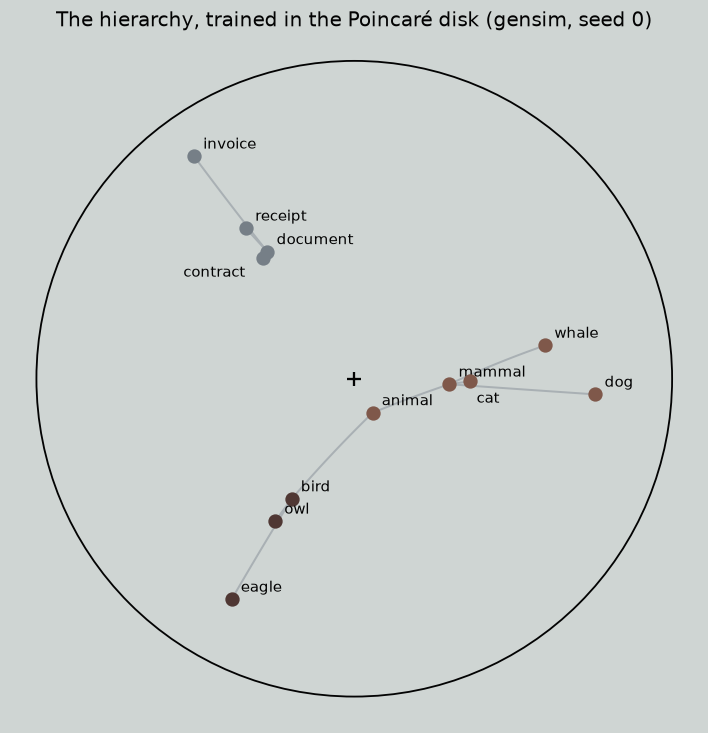

In [7]:
branch_colour = {}
for w in ["animal", "mammal", "dog", "cat", "whale"]: branch_colour[w] = BROWN
for w in ["bird", "eagle", "owl"]: branch_colour[w] = DARK_BROWN
for w in ["document", "invoice", "receipt", "contract"]: branch_colour[w] = SLATE

fig, ax = plt.subplots(figsize=(6.8, 6.8))
draw_disk(ax, "The hierarchy, trained in the Poincaré disk (gensim, seed 0)")
for child, parent in rels:
    g = geodesic(complex(*emb[child]), complex(*emb[parent]))
    ax.plot(g.real, g.imag, color=LIGHT_GREY, lw=1.3, zorder=1)
for w, v in emb.items():
    ax.scatter(*v, s=70, color=branch_colour[w], zorder=3)
    ax.annotate(w, v, xytext={"cat": (4, -14), "contract": (-52, -12)}.get(w, (6, 5)), textcoords="offset points", fontsize=10)
ax.scatter(0, 0, marker="+", s=80, color=TEXT)
plt.tight_layout(); plt.show()

**What you're seeing:** each branch heads off in its own direction. Documents go up and to the left, birds down and to the left, mammals to the right, and animal sits between its two branches near the centre. So norm is roughly depth and direction is roughly branch. The document branch is nowhere near the animals, which is exactly what you want from a hierarchy where they share no ancestor.

## Step 5 · Flat vs hyperbolic, same data

The toy hierarchy above is too small to stress flat space (twelve words fit comfortably almost anywhere), so for a fair race we use a bigger tree. It's a complete tree with branching factor 3 and depth 4, which gives 121 nodes. Following Nickel & Kiela, every node is linked to **all** of its ancestors (so a leaf is linked to its parent, grandparent and so on up to the root), which gives 426 "is a" pairs.

Both embeddings get exactly the same treatment:

- **2 dimensions**, same random start, seed 0.
- **Same loss** (Nickel & Kiela, NeurIPS 2017). For each linked pair $(u, v)$ the loss pushes $d(u, v)$ down compared with the distances from $u$ to every node it isn't linked to: $-\log \frac{e^{-d(u,v)}}{\sum_{v'} e^{-d(u,v')}}$.
- **Same optimiser and budget**: 3,000 full-batch steps of Riemannian Adam with learning rate 0.01. In flat space Riemannian Adam is just ordinary Adam. We use the geoopt library here, and Step 6 unpacks what it does.

The only difference is the distance $d$: hyperbolic in one, Euclidean in the other.

To score them we use the reconstruction metrics from the paper. For every linked pair $(u, v)$ we ask how many *unlinked* nodes are closer to $u$ than $v$ is. **Mean rank** averages that position (1 is perfect), and **MAP** (mean average precision) summarises how well all of $u$'s true links come before everything else (1.0 is perfect).

In [8]:
def make_tree(branching, depth):
    parent, frontier, nxt = {}, [0], 1
    for _ in range(depth):
        new = []
        for p in frontier:
            for _ in range(branching):
                parent[nxt] = p; new.append(nxt); nxt += 1
        frontier = new
    return nxt, parent

def ancestor_pairs(parent):
    pairs = []
    for u in parent:
        p = parent[u]
        while p is not None:
            pairs.append((u, p)); p = parent.get(p)
    return pairs

n, parent = make_tree(3, 4)
pairs = ancestor_pairs(parent)
depth = np.zeros(n, int)
for u in range(1, n):
    depth[u] = depth[parent[u]] + 1
print(f"{n} nodes, {len(pairs)} 'is a' pairs")

linked = torch.zeros(n, n, dtype=torch.bool)
for u, v in pairs:
    linked[u, v] = linked[v, u] = True
U = torch.tensor([u for u, v in pairs] + [v for u, v in pairs])
V = torch.tensor([v for u, v in pairs] + [u for u, v in pairs])

def all_distances(X, manifold):
    if isinstance(manifold, geoopt.PoincareBall):
        return manifold.dist(X[:, None, :], X[None, :, :])
    return (X[:, None, :] - X[None, :, :]).norm(dim=-1).clamp_min(1e-12)

def train(manifold, steps=3000, lr=0.01):
    torch.manual_seed(SEED)
    start = torch.empty(n, 2, dtype=torch.float64).uniform_(-1e-3, 1e-3)
    X = geoopt.ManifoldParameter(start, manifold=manifold)
    opt = geoopt.optim.RiemannianAdam([X], lr=lr)
    rows = torch.arange(len(U))
    skip = linked[U].clone(); skip[rows, V] = False; skip[rows, U] = True   # compare v only with unlinked nodes
    for _ in range(steps):
        opt.zero_grad()
        D = all_distances(X, manifold)
        logits = (-D[U]).masked_fill(skip, -1e9)
        loss = (torch.logsumexp(logits, dim=1) + D[U, V]).mean()
        loss.backward()
        opt.step()
    return X.detach()

def reconstruction(X, manifold):
    D = all_distances(X, manifold).numpy()
    ranks, aps = [], []
    for u in range(n):
        links = np.where(linked[u].numpy())[0]
        unlinked = np.array([v for v in range(n) if v != u and not linked[u, v]], dtype=int)
        for v in links:
            ranks.append(1 + (D[u, unlinked] < D[u, v]).sum())
        order = [v for v in np.argsort(D[u]) if v != u]
        hits, precisions = 0, []
        for i, v in enumerate(order, 1):
            if linked[u, v]:
                hits += 1; precisions.append(hits / i)
        aps.append(np.mean(precisions))
    return float(np.mean(ranks)), float(np.mean(aps))

ball, flat = geoopt.PoincareBall(c=1.0), geoopt.Euclidean(ndim=1)
X_hyp, X_flat = train(ball), train(flat)
results = {"Hyperbolic (Poincaré), 2-d": reconstruction(X_hyp, ball),
           "Flat (Euclidean), 2-d": reconstruction(X_flat, flat)}

print(f"\n{'':<30}{'mean rank':>10}{'MAP':>8}")
for name, (mr, mp) in results.items():
    print(f"{name:<30}{mr:10.2f}{mp:8.3f}")

121 nodes, 426 'is a' pairs



                               mean rank     MAP
Hyperbolic (Poincaré), 2-d          2.14   0.954
Flat (Euclidean), 2-d               6.44   0.599


**What you're seeing:** same tree, same loss, same optimiser, same number of steps, same seed, and the only change is the distance function. The hyperbolic embedding reaches a MAP of 0.954 with a mean rank of 2.14. The flat one manages 0.599 with a mean rank of 6.44, which means that on average about five unrelated nodes sit closer to a node than one of its true ancestors.

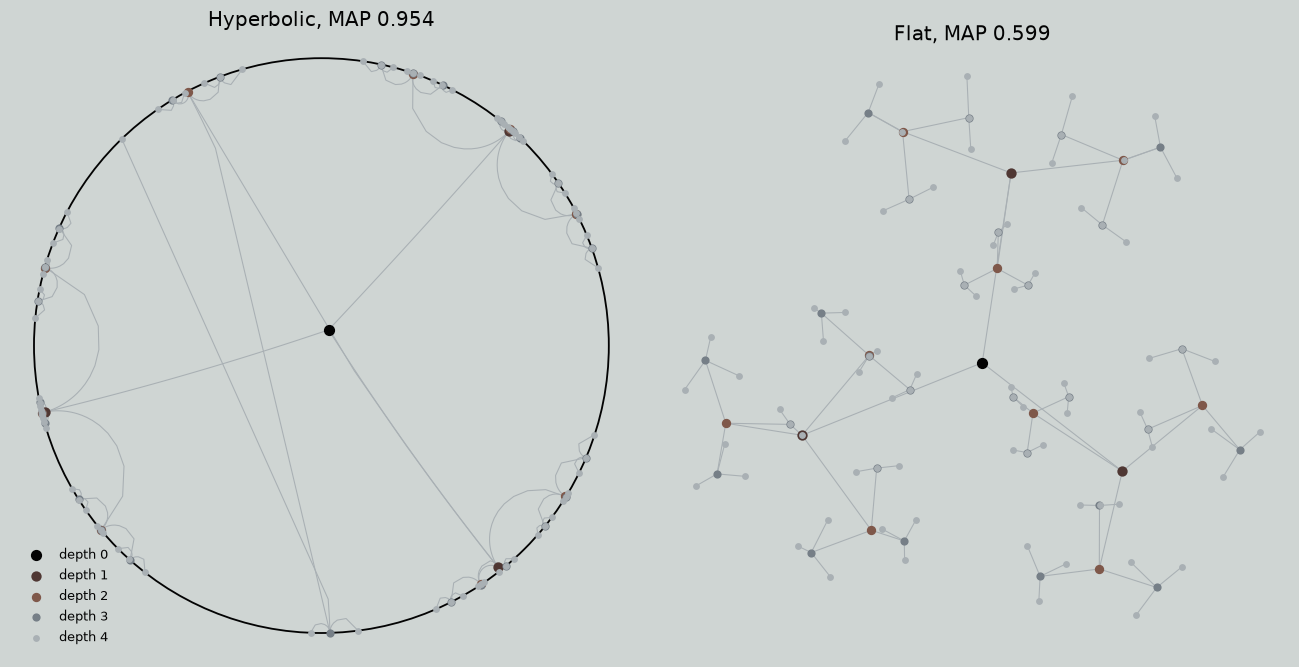

In [9]:
depth_colour = [TEXT, DARK_BROWN, BROWN, SLATE, LIGHT_GREY]
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

ax = axes[0]
draw_disk(ax, f"Hyperbolic, MAP {results['Hyperbolic (Poincaré), 2-d'][1]:.3f}")
Z = X_hyp[:, 0].numpy() + 1j * X_hyp[:, 1].numpy()
for u, p in parent.items():
    g = geodesic(Z[p], Z[u]); ax.plot(g.real, g.imag, color=LIGHT_GREY, lw=0.7, zorder=1)
for k in range(5):
    idx = depth == k
    ax.scatter(Z[idx].real, Z[idx].imag, s=40 - 7 * k, color=depth_colour[k], zorder=3, label=f"depth {k}")
ax.legend(frameon=False, loc="lower left", fontsize=8.5)

ax = axes[1]
Y = X_flat.numpy()
for u, p in parent.items():
    ax.plot(*zip(Y[p], Y[u]), color=LIGHT_GREY, lw=0.7, zorder=1)
for k in range(5):
    idx = depth == k
    ax.scatter(Y[idx, 0], Y[idx, 1], s=40 - 7 * k, color=depth_colour[k], zorder=3)
ax.set_aspect("equal"); ax.axis("off")
ax.set_title(f"Flat, MAP {results['Flat (Euclidean), 2-d'][1]:.3f}")
plt.tight_layout(); plt.show()

**What you're seeing:** the flat picture looks like a perfectly nice drawing of a tree, and that's what makes it sneaky. The problem is what the drawing doesn't show. Every leaf has to be closer to its parent, its grandparent and the root than to any node in another branch, and in the plane there isn't room to keep all of those promises at once, so neighbouring subtrees spill into each other. The hyperbolic picture looks squashed against the edge because that's where the room is on paper. Measured with hyperbolic distance, those crowded-looking points are far apart.

The published numbers tell the same story at a much bigger scale. On the WordNet noun hierarchy (about 82,000 nouns), Nickel & Kiela (NeurIPS 2017, Table 1) report:

| Embedding | Dimensions | MAP | Mean rank |
|---|---|---|---|
| Poincaré | 5 | 0.823 | 4.9 |
| Euclidean | 200 | 0.168 | 1,157.3 |

Five hyperbolic dimensions beat two hundred flat ones by a mile. And if you skip learning altogether and build the embedding combinatorially from the tree, Sala, De Sa, Gu & Ré (ICML 2018) reach a MAP of 0.989 on WordNet in **2** dimensions (with a catch we'll get to in Step 8).

## Step 6 · geoopt

In Step 5 we leaned on geoopt (Kochurov, Karimov & Kozlukov, arXiv 2020), a PyTorch library for optimisation on curved spaces. Three pieces did the work:

- `geoopt.PoincareBall(c=1.0)` is the Poincaré ball with curvature $-c$, so $c = 1$ is the standard hyperbolic space. It gives you the distance (`dist`) and the maps in and out of the curved space.
- `expmap0` takes an ordinary vector (a direction and a length, starting at the centre) and walks that far along the curved space. `logmap0` goes back. It's the standard way to turn the output of a normal neural network into a point in the ball.
- `geoopt.optim.RiemannianAdam` and `RiemannianSGD` are optimisers that follow the curve. A plain gradient step in the ball can overshoot and land outside the disk, where the distance formula stops making sense. The Riemannian versions rescale the gradient for the local geometry and step along the space, so points always stay inside.

Let's check geoopt against our hand-written formula from Step 3. One detail to expect: at the centre of the ball the curved metric is twice the flat one (the factor $2/(1-\lVert x \rVert^2)$ in the Poincaré metric equals 2 at $x = 0$), so a tangent vector of length $\ell$ lands at hyperbolic distance $2\ell$ from the centre.

In [10]:
ball = geoopt.PoincareBall(c=1.0)

tangent = torch.tensor([[0.5, 0.0], [0.0, 1.0], [-1.0, 1.0]], dtype=torch.float64)   # ordinary vectors at the centre
points = ball.expmap0(tangent)                                                        # walked onto the ball
back = ball.logmap0(points)

print("tangent vector lengths:           ", np.round(tangent.norm(dim=1).numpy(), 4))
print("expmap0 places them at norms:     ", np.round(points.norm(dim=1).numpy(), 4), " = tanh(length)")
print("hyperbolic distance from centre:  ", np.round(ball.dist0(points).numpy(), 4), " = 2 x length")
print("logmap0 brings back the vectors:  ", np.allclose(back.numpy(), tangent.numpy(), atol=1e-6))

geo = ball.dist(points[0], points[2]).item()
mine = poincare_dist(points[0].numpy(), points[2].numpy())
print(f"\ngeoopt dist {geo:.9f}\nour numpy   {mine:.9f}")

tangent vector lengths:            [0.5    1.     1.4142]
expmap0 places them at norms:      [0.4621 0.7616 0.8884]  = tanh(length)
hyperbolic distance from centre:   [1.     2.     2.8284]  = 2 x length
logmap0 brings back the vectors:   True

geoopt dist 3.693462990
our numpy   3.693463433


**What you're seeing:** tangent vectors of length 0.5, 1 and 1.41 land at norms $\tanh(\text{length})$, and at hyperbolic distance exactly twice their length from the centre, as promised. `logmap0` gets the original vectors back, and geoopt's distance matches our numpy formula to about $4 \times 10^{-7}$. The tiny difference is deliberate, because geoopt keeps points a hair away from the edge for numerical safety, which is the precision problem from Step 8 showing up early.

## Step 7 · Results from retrieval and LLMs

Trees on paper are one thing. Here's what happens when people put hyperbolic geometry into real systems.

**Retrieval.** HypRAG (Madhu et al., ICML 2026) trains a hyperbolic dense retriever the same size as a Euclidean BERT-style retriever (149M parameters, 768 dimensions) and plugs both into a RAG pipeline. Averaged over RAGBench:

| Metric | Euclidean | Hyperbolic (HypRAG) |
|---|---|---|
| Faithfulness | 0.596 | 0.732 |
| Context relevance | 0.798 | 0.848 |
| Answer relevance | 0.647 | 0.765 |

Same parameter count, same dimension, and the curved version wins on every column.

**Images and text.** MERU (Desai et al., ICML 2023) learns hyperbolic image–text representations and is competitive with CLIP, with the bonus that generic concepts ("animal") sit near the centre and specific images sit further out, which is exactly the norm-as-depth pattern from Step 4.

**LLMs.** HELM (He et al., NeurIPS 2025) builds hyperbolic large language models and reports gains of up to 4% over Euclidean LLaMA-style and DeepSeek-style models on MMLU and ARC.

Hyperbolic space won't win everywhere. But when your data has a hierarchy in it, and most enterprise data does, sticking with flat space costs you accuracy.

## Step 8 · The costs

I'd be selling you something if I stopped there. Curved spaces have real costs.

**Precision near the edge.** All the room in the Poincaré disk is near the edge, and that's exactly where floating-point numbers run out of digits. Sala et al. (ICML 2018) show that their exact 2-dimensional construction needs about 500 bits per number. With ordinary 32-bit floats you need more dimensions, around 10, to get the same quality. Our own trained tree from Step 5 already shows the problem.

In [11]:
far = X_hyp.norm(dim=1).max().item()
print(f"Furthest node in our trained tree: norm {far:.10f}, so it sits {1 - far:.1e} from the edge")
print(f"Its hyperbolic distance from the centre: {2 * np.arctanh(far):.2f}")

for name, dtype in [("float32", np.float32), ("float64", np.float64)]:
    eps = np.spacing(dtype(1)) / 2                 # distance from 1 down to the largest float below it
    left = int((1 - far) / eps)
    max_d = 2 * np.arctanh(1 - np.float64(eps))    # the furthest point you can store before rounding to 1.0
    print(f"\n{name}: about {left:,} representable values left between that node and the edge")
    print(f"{name}: nothing can sit further than {max_d:.1f} from the centre before the norm rounds to 1.0 and the distance becomes inf")

Furthest node in our trained tree: norm 0.9999901056, so it sits 9.9e-06 from the edge
Its hyperbolic distance from the centre: 12.22

float32: about 166 representable values left between that node and the edge
float32: nothing can sit further than 17.3 from the centre before the norm rounds to 1.0 and the distance becomes inf

float64: about 89,120,571,393 representable values left between that node and the edge
float64: nothing can sit further than 37.4 from the centre before the norm rounds to 1.0 and the distance becomes inf


**What you're seeing:** our furthest node is only $10^{-5}$ from the edge, at hyperbolic distance 12.2 from the centre. In float32 there are only about 166 representable numbers left between it and the edge, and float32 can't store any point further than 17.3 from the centre at all, because its norm rounds to exactly 1.0 and the distance becomes infinite. Every level of a tree costs a fixed amount of distance, so float32 puts a hard limit on how deep a tree you can draw. float64 pushes that limit to 37.4. This is why the exact 2-d constructions need so many bits.

**Optimisation.** You need Riemannian optimisers (Step 6), careful learning rates and often a "burn-in" phase with a small learning rate at the start, as Nickel & Kiela use. Most of the deep learning toolbox assumes flat space, so every layer and every trick has to be rethought.

**Vector databases.** pgvector, FAISS, Pinecone and friends index cosine, dot product and Euclidean distance. There's no built-in hyperbolic index, so in production you either compute distances by brute force or fetch candidates with a flat index and re-rank them hyperbolically (notebook 04 shows both).

Two ideas help. The **Lorentz model** (Nickel & Kiela, ICML 2018) represents the same hyperbolic space as a bowl-shaped surface with no edge, which makes training much more stable. And **product manifolds** (Gu, Sala, Gunel & Ré, ICLR 2019) glue together hyperbolic, spherical and flat pieces and learn the curvature of each from the data, because real data is rarely just one shape.

## Takeaway

Trees grow exponentially and so does hyperbolic space, and on the same data with the same budget a 2-dimensional hyperbolic embedding reconstructs a hierarchy far better than a flat one. You pay for it in precision, optimisation and tooling, and in notebook 03 we step back to ask a more basic question: what does it actually mean to choose a geometry?